<a href="https://colab.research.google.com/github/anamaciel149/DL_cibernetico/blob/main/TRAB_DL_Ciberseguranca_UNSW_NB15_FINAL_Colab_VSCode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNIVERSIDADE DE BRASÍLIA
## Departamento de Engenharia de Produção

# MVP — Deep Learning aplicado à Segurança Cibernética

**Tema:** Detecção de intrusões em redes utilizando Deep Learning  
**Base:** UNSW-NB15  
**Ambientes suportados:** Google Colab e VS Code / Jupyter local  
**Versão final do projeto**

> O notebook identifica automaticamente o ambiente, instala apenas dependências ausentes,
> baixa a base pelo KaggleHub, corrige o split oficial quando necessário, treina a DNN,
> escolhe o threshold na validação e avalia o modelo somente no conjunto oficial de teste.


# 1. Apresentação

## 1.1 Problema
Ambientes computacionais produzem grande volume de tráfego de rede, tornando inviável a inspeção manual de todas as conexões. Este MVP investiga o uso de Deep Learning para identificar automaticamente padrões associados a tráfego malicioso.

## 1.2 Hipótese
> Uma rede neural profunda treinada com características de tráfego de rede consegue distinguir registros normais de ataques com desempenho útil, especialmente em recall e F1-score.

## 1.3 Critério de sucesso
Serão analisados:
- Precision
- Recall
- F1-score
- ROC-AUC
- Matriz de confusão

A acurácia será reportada, mas não interpretada isoladamente.

# 2. Objetivo e perguntas

## 2.1 Objetivo geral
Construir um pipeline reproduzível que obtenha a base UNSW-NB15, avalie sua qualidade, prepare os dados, treine uma rede neural profunda e avalie criticamente seu desempenho na detecção de intrusões.

## 2.2 Perguntas
1. Qual é a distribuição entre tráfego normal e ataques?
2. Existem problemas de qualidade capazes de comprometer a modelagem?
3. Uma DNN consegue distinguir tráfego normal de tráfego malicioso?
4. Qual é o desempenho em precision, recall, F1-score e ROC-AUC?
5. Quantos ataques deixam de ser detectados?
6. Quais limitações impedem considerar o MVP pronto para produção?

## 2.3 Plataforma
O notebook foi preparado para Google Colab. A base é baixada do Kaggle e os resultados podem ser persistidos no Google Drive.

# 3. Detalhamento das etapas

## 3.1 Busca pelos dados
A base escolhida é a **UNSW-NB15**, utilizada em estudos de detecção de intrusões. O alvo `label` representa:

- `0`: tráfego normal
- `1`: ataque

A coluna `attack_cat` será retirada das entradas do modelo binário para evitar vazamento de informação.

In [1]:
import sys
import subprocess
import importlib.util

try:
    import google.colab  # type: ignore
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

# TensorFlow 2.21 é compatível com Python 3.12 usado neste projeto.
# No VS Code, se você estiver em Python >= 3.14, selecione o ambiente .venv-dl com Python 3.12.
if not IS_COLAB and sys.version_info >= (3, 14):
    raise RuntimeError(
        "Este notebook requer um Python compatível com TensorFlow. "
        "No VS Code, selecione o ambiente .venv-dl com Python 3.12."
    )

required = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "pyarrow": "pyarrow",
    "kagglehub": "kagglehub",
    "tensorflow": "tensorflow",
}

missing = [
    pip_name
    for module_name, pip_name in required.items()
    if importlib.util.find_spec(module_name) is None
]

if missing:
    print("Pacotes ausentes:", missing)
    print("Instalando apenas o que está faltando...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", *missing
    ])
else:
    print("Todos os pacotes necessários já estão instalados.")

print("Ambiente:", "Google Colab" if IS_COLAB else "VS Code / Jupyter local")
print("Python:", sys.version.split()[0])
print("Executável:", sys.executable)


Todos os pacotes necessários já estão instalados.
Ambiente: Google Colab
Python: 3.13.18
Executável: /usr/bin/python3


In [2]:
import random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Reprodutibilidade adicional quando suportada pelo backend.
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Execução:", datetime.now().astimezone().isoformat())


TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3
Execução: 2026-11-09T22:33:14.819080+00:00


## 3.2 Coleta
A coleta é automatizada via KaggleHub. O notebook registra origem, data, formato e volume dos arquivos.

In [3]:
import kagglehub

KAGGLE_DATASET = "mrwellsdavid/unsw-nb15"
coleta_em = datetime.now().astimezone().isoformat()

dataset_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
all_files = sorted([p for p in dataset_path.rglob("*") if p.is_file()])

coleta_info = pd.DataFrame([{
    "arquivo": p.name,
    "formato": p.suffix.lower().replace(".", ""),
    "tamanho_mb": round(p.stat().st_size / (1024**2), 3),
    "origem": f"Kaggle: {KAGGLE_DATASET}",
    "coletado_em": coleta_em
} for p in all_files])

display(coleta_info)

Using Colab cache for faster access to the 'unsw-nb15' dataset.


,arquivo,formato,tamanho_mb,origem,coletado_em
0,NUSW-NB15_features.csv,csv,0.004,Kaggle: mrwellsdavid/unsw-nb15,2026-11-09T22:33:17.647801+00:00
1,UNSW-NB15_1.csv,csv,161.152,Kaggle: mrwellsdavid/unsw-nb15,2026-11-09T22:33:17.647801+00:00
2,UNSW-NB15_2.csv,csv,157.567,Kaggle: mrwellsdavid/unsw-nb15,2026-11-09T22:33:17.647801+00:00
3,UNSW-NB15_3.csv,csv,147.427,Kaggle: mrwellsdavid/unsw-nb15,2026-11-09T22:33:17.647801+00:00
4,UNSW-NB15_4.csv,csv,93.068,Kaggle: mrwellsdavid/unsw-nb15,2026-11-09T22:33:17.647801+00:00
5,UNSW-NB15_LIST_EVENTS.csv,csv,0.004,Kaggle: mrwellsdavid/unsw-nb15,2026-11-09T22:33:17.647801+00:00
6,UNSW_NB15_testing-set.csv,csv,30.797,Kaggle: mrwellsdavid/unsw-nb15,2026-11-09T22:33:17.647801+00:00
7,UNSW_NB15_training-set.csv,csv,14.668,Kaggle: mrwellsdavid/unsw-nb15,2026-11-09T22:33:17.647801+00:00


In [4]:
def choose_file(files, split):
    keys = ["training-set", "training_set", "train"] if split == "train" else ["testing-set", "testing_set", "test"]
    valid = [p for p in files if p.suffix.lower() in {".csv", ".parquet"}]
    found = [p for p in valid if any(k in p.name.lower() for k in keys)]
    if not found:
        raise FileNotFoundError(f"Arquivo de {split} não encontrado.")
    return sorted(
        found,
        key=lambda p: (0 if p.suffix.lower() == ".parquet" else 1, len(p.name))
    )[0]

def read_table(p):
    return pd.read_parquet(p) if p.suffix.lower() == ".parquet" else pd.read_csv(p)

train_file = choose_file(all_files, "train")
test_file = choose_file(all_files, "test")

train_df = read_table(train_file)
test_df = read_table(test_file)

print("Arquivos encontrados pelo nome:")
print("Treino:", train_file.name, train_df.shape)
print("Teste :", test_file.name, test_df.shape)

# A partição oficial da UNSW-NB15 usada no trabalho é:
# treino = 175.341 registros | teste = 82.332 registros.
# Alguns espelhos do Kaggle usam nomes trocados; por isso validamos pelo tamanho.
if len(train_df) == 82332 and len(test_df) == 175341:
    print("\nSplit do espelho Kaggle detectado com nomes invertidos.")
    print("Ajustando para o split oficial da UNSW-NB15...")
    train_df, test_df = test_df.copy(), train_df.copy()

if len(train_df) != 175341 or len(test_df) != 82332:
    raise ValueError(
        "As dimensões carregadas não correspondem ao split oficial esperado "
        "(treino=175341, teste=82332). Verifique a versão da base."
    )

print("\nSplit oficial confirmado:")
print("Treino oficial:", train_df.shape)
print("Teste oficial :", test_df.shape)
display(train_df.head())


Arquivos encontrados pelo nome:
Treino: UNSW_NB15_training-set.csv (82332, 45)
Teste : UNSW_NB15_testing-set.csv (175341, 45)

Split do espelho Kaggle detectado com nomes invertidos.
Ajustando para o split oficial da UNSW-NB15...

Split oficial confirmado:
Treino oficial: (175341, 45)
Teste oficial : (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


## 3.3 Modelagem e Catálogo de Dados

O MVP utiliza uma estrutura **flat**, em que cada linha representa um registro/fluxo de tráfego.

**Linhagem:** Kaggle → leitura → análise de qualidade → pré-processamento → DNN → métricas.

O catálogo é gerado automaticamente com tipo, domínio observado, nulos, cardinalidade e origem.

In [5]:
def build_catalog(df, origem):
    rows = []
    for col in df.columns:
        s = df[col]
        if pd.api.types.is_numeric_dtype(s):
            tipo = "Numérico"
            dominio = "Sem valores" if s.dropna().empty else f"[{s.min()}, {s.max()}]"
        else:
            tipo = "Categórico/Texto"
            vals = s.dropna().astype(str).value_counts().head(12).index.tolist()
            dominio = ", ".join(vals) + (", ..." if s.nunique(dropna=True) > 12 else "")
        desc = (
            "Rótulo binário: 0=normal; 1=ataque." if col=="label" else
            "Categoria do ataque; removida das entradas do modelo." if col=="attack_cat" else
            "Identificador do registro; removido da modelagem." if col=="id" else
            "Atributo da base UNSW-NB15."
        )
        rows.append({
            "atributo": col,
            "tipo": tipo,
            "descricao": desc,
            "dominio_observado": dominio,
            "nulos": int(s.isna().sum()),
            "cardinalidade": int(s.nunique(dropna=True)),
            "linhagem": origem
        })
    return pd.DataFrame(rows)

catalogo = build_catalog(train_df, f"Kaggle/{KAGGLE_DATASET}/{train_file.name}")
display(catalogo)
catalogo.to_csv("catalogo_dados_unsw_nb15.csv", index=False)

,atributo,tipo,descricao,dominio_observado,nulos,cardinalidade,linhagem
0,id,Numérico,Identificador do registro; removido da modelagem.,"[1, 175341]",0,175341,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
1,dur,Numérico,Atributo da base UNSW-NB15.,"[0.0, 59.999989]",0,74039,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
2,proto,Categórico/Texto,Atributo da base UNSW-NB15.,"tcp, udp, unas, arp, ospf, sctp, any, gre, ipv...",0,133,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
3,service,Categórico/Texto,Atributo da base UNSW-NB15.,"-, dns, http, smtp, ftp-data, ftp, ssh, pop3, ...",0,13,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
4,state,Categórico/Texto,Atributo da base UNSW-NB15.,"INT, FIN, CON, REQ, RST, ECO, PAR, URN, no",0,9,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
5,spkts,Numérico,Atributo da base UNSW-NB15.,"[1, 9616]",0,480,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
6,dpkts,Numérico,Atributo da base UNSW-NB15.,"[0, 10974]",0,443,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
7,sbytes,Numérico,Atributo da base UNSW-NB15.,"[28, 12965233]",0,7214,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
8,dbytes,Numérico,Atributo da base UNSW-NB15.,"[0, 14655550]",0,6660,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...
9,rate,Numérico,Atributo da base UNSW-NB15.,"[0.0, 1000000.003]",0,76991,Kaggle/mrwellsdavid/unsw-nb15/UNSW_NB15_traini...


## 3.4 Carga e persistência

A pasta de resultados é configurada automaticamente:

- **Google Colab:** tenta montar o Google Drive e usa `MyDrive/TRAB_DL_CIBERSEGURANCA`;
- **VS Code/Jupyter local:** cria a pasta `resultados` no diretório atual;
- caso o Drive não possa ser montado no Colab, usa `/content/resultados`.

Além dos dados e métricas, o notebook também exporta gráficos e o modelo treinado.

In [6]:
if IS_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PERSIST_DIR = Path("/content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA")
        print("Google Drive montado.")
    except Exception as e:
        PERSIST_DIR = Path("/content/resultados")
        print("Não foi possível montar o Google Drive.")
        print("Usando armazenamento temporário do Colab.")
        print("Detalhe:", e)
else:
    PERSIST_DIR = Path.cwd() / "resultados"

PERSIST_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PERSIST_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

coleta_info.to_csv(PERSIST_DIR / "evidencia_coleta.csv", index=False)
catalogo.to_csv(PERSIST_DIR / "catalogo_dados_unsw_nb15.csv", index=False)
train_df.to_parquet(PERSIST_DIR / "UNSW_NB15_training-set.parquet", index=False)
test_df.to_parquet(PERSIST_DIR / "UNSW_NB15_testing-set.parquet", index=False)

print("Resultados serão salvos em:")
print(PERSIST_DIR.resolve())

Mounted at /content/drive
Google Drive montado.
Resultados serão salvos em:
/content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA


## 3.5 Análise

### 3.5.1 Qualidade dos dados
Serão observadas completude, unicidade, consistência, conformidade e plausibilidade.

In [7]:
train_df = train_df.replace([np.inf, -np.inf], np.nan).copy()
test_df = test_df.replace([np.inf, -np.inf], np.nan).copy()

quality = pd.DataFrame([{
    "atributo": c,
    "nulos": int(train_df[c].isna().sum()),
    "pct_nulos": round(100 * train_df[c].isna().mean(), 4),
    "unicos": int(train_df[c].nunique(dropna=True)),
    "tipo": str(train_df[c].dtype)
} for c in train_df.columns])

print("Duplicatas completas no treino:", int(train_df.duplicated().sum()))
print("Duplicatas completas no teste:", int(test_df.duplicated().sum()))

if "label" in train_df.columns:
    print("Classes observadas em label:", sorted(train_df["label"].dropna().unique().tolist()))

display(quality.sort_values(["pct_nulos", "atributo"], ascending=[False, True]))

quality.to_csv(PERSIST_DIR / "qualidade_dados.csv", index=False)
print("Análise de qualidade salva em:", PERSIST_DIR / "qualidade_dados.csv")

Duplicatas completas no treino: 0
Duplicatas completas no teste: 0
Classes observadas em label: [0, 1]


,atributo,nulos,pct_nulos,unicos,tipo
26,ackdat,0,0.0,37708,float64
43,attack_cat,0,0.0,10,object
33,ct_dst_ltm,0,0.0,50,int64
35,ct_dst_sport_ltm,0,0.0,32,int64
36,ct_dst_src_ltm,0,0.0,54,int64
39,ct_flw_http_mthd,0,0.0,11,int64
38,ct_ftp_cmd,0,0.0,4,int64
34,ct_src_dport_ltm,0,0.0,47,int64
40,ct_src_ltm,0,0.0,50,int64
41,ct_srv_dst,0,0.0,52,int64


Análise de qualidade salva em: /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA/qualidade_dados.csv


### 3.5.2 Pergunta 1 — Distribuição das classes

,quantidade,percentual
label,,
0,56000,31.937767
1,119341,68.062233


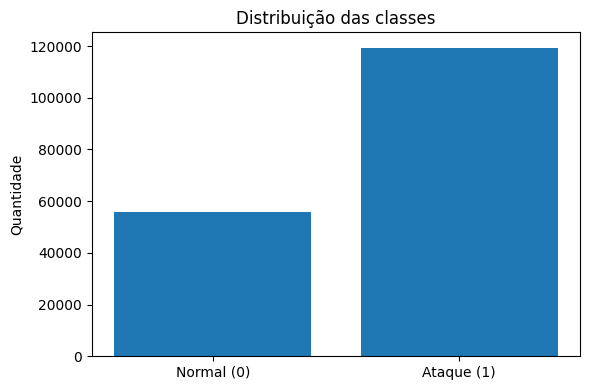

Gráfico salvo em: /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA/figuras/distribuicao_classes.png


In [8]:
counts = train_df["label"].value_counts().sort_index()

display(
    counts.rename_axis("label").to_frame("quantidade")
    .assign(percentual=lambda x: 100 * x["quantidade"] / x["quantidade"].sum())
)

plt.figure(figsize=(6, 4))
plt.bar(["Normal (0)", "Ataque (1)"], counts.values)
plt.title("Distribuição das classes")
plt.ylabel("Quantidade")
plt.tight_layout()

class_plot = FIG_DIR / "distribuicao_classes.png"
plt.savefig(class_plot, dpi=180, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", class_plot)

### 3.5.3 Preparação dos dados

Regras:
- `label` = alvo;
- `attack_cat` removida para evitar leakage;
- `id` removido;
- numéricas: imputação + padronização;
- categóricas: imputação + One-Hot Encoding;
- treino oficial dividido em treino interno e validação;
- teste oficial preservado para avaliação final.

In [9]:
train_df = train_df.dropna(subset=["label"]).copy()
test_df = test_df.dropna(subset=["label"]).copy()

train_df["label"] = train_df["label"].astype(int)
test_df["label"] = test_df["label"].astype(int)

drop_train = [c for c in ["label","attack_cat","id"] if c in train_df.columns]
drop_test = [c for c in ["label","attack_cat","id"] if c in test_df.columns]

X_full = train_df.drop(columns=drop_train)
y_full = train_df["label"]
X_test_raw = test_df.drop(columns=drop_test).reindex(columns=X_full.columns)
y_test = test_df["label"]

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.20, stratify=y_full, random_state=SEED
)

num_cols = X_train_raw.select_dtypes(include=[np.number,"bool"]).columns.tolist()
cat_cols = [c for c in X_train_raw.columns if c not in num_cols]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32))
])

prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

X_train = prep.fit_transform(X_train_raw).astype(np.float32)
X_val = prep.transform(X_val_raw).astype(np.float32)
X_test = prep.transform(X_test_raw).astype(np.float32)

print(X_train.shape, X_val.shape, X_test.shape)

(140272, 192) (35069, 192) (82332, 192)


### 3.5.4 Modelo de Deep Learning

Arquitetura:

**Entrada → Dense 128 → Dense 64 → Dense 32 → Sigmoid**

São utilizados ReLU, Batch Normalization, Dropout, Adam, Binary Cross-Entropy e Early Stopping.

In [10]:
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c,w in zip(classes,weights)}

model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.30),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.30),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,841 (140.00 KB)

 Trainable params: 35,457 (138.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [11]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=256,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9034 - auc: 0.9702 - loss: 0.2106 - precision: 0.9397 - recall: 0.9169 - val_accuracy: 0.9196 - val_auc: 0.9867 - val_loss: 0.1431 - val_precision: 0.9721 - val_recall: 0.9080 - learning_rate: 0.0010
Epoch 2/30
548/548 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9213 - auc: 0.9842 - loss: 0.1511 - precision: 0.9616 - recall: 0.9213 - val_accuracy: 0.9217 - val_auc: 0.9876 - val_loss: 0.1375 - val_precision: 0.9750 - val_recall: 0.9083 - learning_rate: 0.0010
Epoch 3/30
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9250 - auc: 0.9856 - loss: 0.1447 - precision: 0.9660 - recall: 0.9222 - val_accuracy: 0.9241 - val_auc: 0.9880 - val_loss: 0.1364 - val_precision: 0.9759 - val_recall: 0.9110 - learning_rate: 0.0010
Epoch 4/30
548/548 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9259 - auc: 0.9861 - loss: 0.1416 - precision: 0.9667 - recall: 0.9230 - val_accuracy: 0.9273 - val_auc: 0.9884 - val_loss: 0.1323 - va

### 3.5.5 Curvas de treinamento

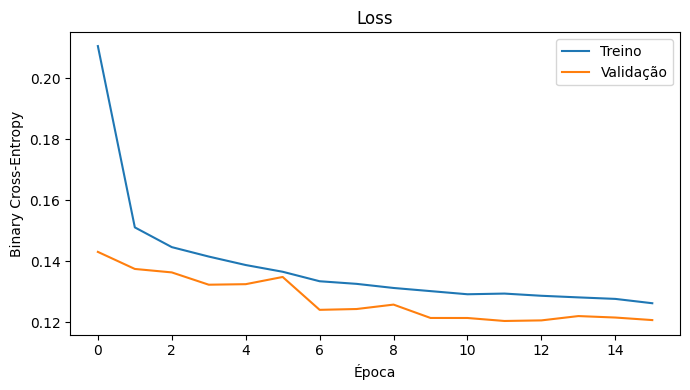

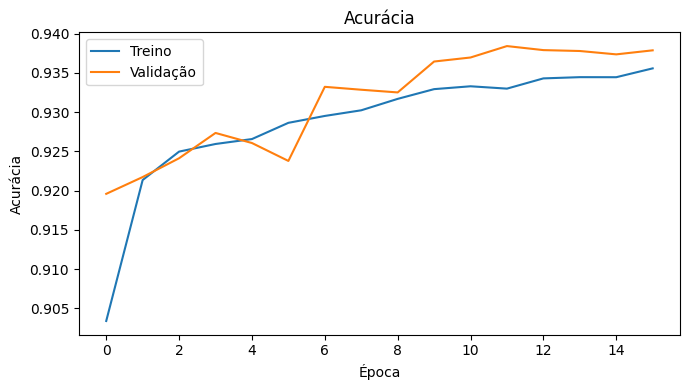

Gráficos salvos em:
- /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA/figuras/curva_loss.png
- /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA/figuras/curva_acuracia.png


In [12]:
hist = pd.DataFrame(history.history)

plt.figure(figsize=(7, 4))
plt.plot(hist["loss"], label="Treino")
plt.plot(hist["val_loss"], label="Validação")
plt.title("Loss")
plt.xlabel("Época")
plt.ylabel("Binary Cross-Entropy")
plt.legend()
plt.tight_layout()
loss_path = FIG_DIR / "curva_loss.png"
plt.savefig(loss_path, dpi=180, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(hist["accuracy"], label="Treino")
plt.plot(hist["val_accuracy"], label="Validação")
plt.title("Acurácia")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.tight_layout()
acc_path = FIG_DIR / "curva_acuracia.png"
plt.savefig(acc_path, dpi=180, bbox_inches="tight")
plt.show()

print("Gráficos salvos em:")
print("-", loss_path)
print("-", acc_path)

### 3.5.6 Escolha do limiar

O limiar será escolhido no conjunto de validação maximizando F1-score. O teste permanece independente.

Melhor threshold: 0.33
F1 validação: 0.96


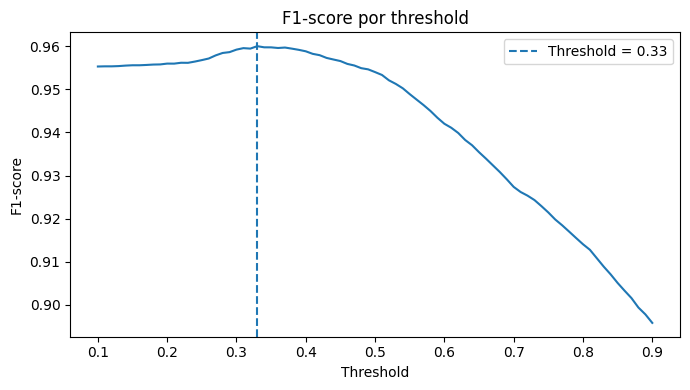

Gráfico salvo em: /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA/figuras/f1_por_threshold.png


In [13]:
val_prob = model.predict(X_val, verbose=0).ravel()
thresholds = np.arange(0.10, 0.91, 0.01)
f1s = [
    f1_score(y_val, (val_prob >= t).astype(int), zero_division=0)
    for t in thresholds
]

best_idx = int(np.argmax(f1s))
best_threshold = float(thresholds[best_idx])
best_val_f1 = float(f1s[best_idx])

print("Melhor threshold:", round(best_threshold, 2))
print("F1 validação:", round(best_val_f1, 4))

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1s)
plt.axvline(best_threshold, linestyle="--", label=f"Threshold = {best_threshold:.2f}")
plt.title("F1-score por threshold")
plt.xlabel("Threshold")
plt.ylabel("F1-score")
plt.legend()
plt.tight_layout()
threshold_path = FIG_DIR / "f1_por_threshold.png"
plt.savefig(threshold_path, dpi=180, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", threshold_path)

### 3.5.7 Avaliação final

In [14]:
test_prob = model.predict(X_test, verbose=0).ravel()
test_pred = (test_prob >= best_threshold).astype(int)

metrics = {
    "Acurácia": accuracy_score(y_test,test_pred),
    "Precision": precision_score(y_test,test_pred,zero_division=0),
    "Recall": recall_score(y_test,test_pred,zero_division=0),
    "F1-score": f1_score(y_test,test_pred,zero_division=0),
    "ROC-AUC": roc_auc_score(y_test,test_prob)
}

metrics_df = pd.DataFrame.from_dict(metrics, orient="index", columns=["Valor"])
display(metrics_df.style.format("{:.4f}"))

print(classification_report(
    y_test,test_pred,target_names=["Normal","Ataque"],digits=4,zero_division=0
))

,Valor
Acurácia,0.8373
Precision,0.7781
Recall,0.9856
F1-score,0.8697
ROC-AUC,0.9744


              precision    recall  f1-score   support

      Normal     0.9738    0.6557    0.7837     37000
      Ataque     0.7781    0.9856    0.8697     45332

    accuracy                         0.8373     82332
   macro avg     0.8759    0.8206    0.8267     82332
weighted avg     0.8660    0.8373    0.8310     82332



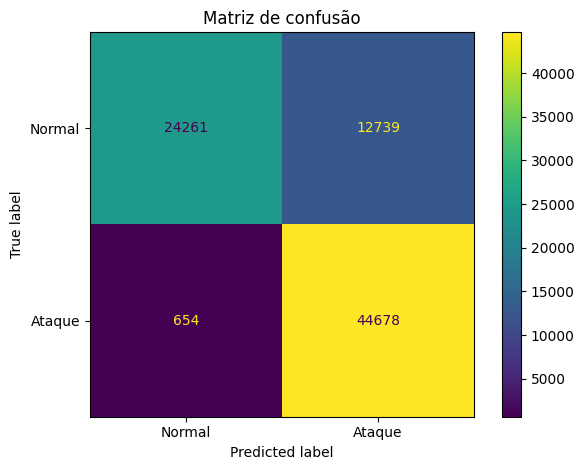

TN — normal corretamente identificado: 24261
FP — normal marcado como ataque       : 12739
FN — ataque não detectado             : 654
TP — ataque corretamente detectado    : 44678


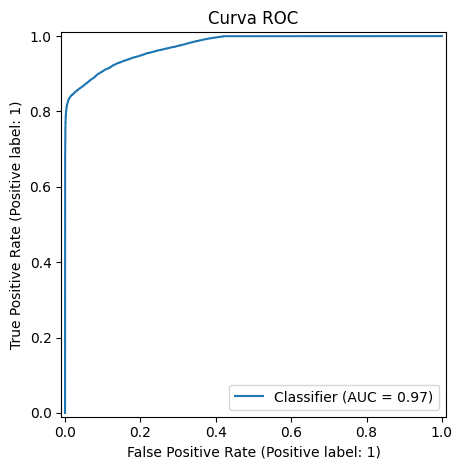

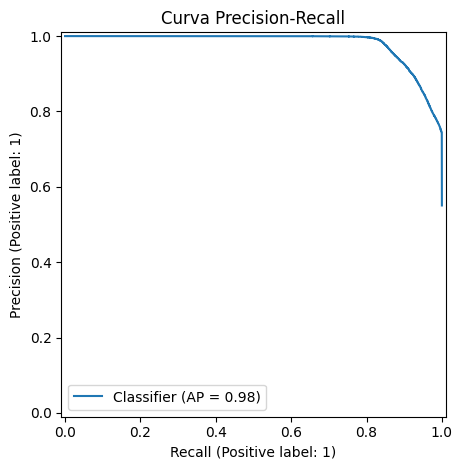

Gráficos salvos em:
- /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA/figuras/matriz_confusao.png
- /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA/figuras/curva_roc.png
- /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA/figuras/curva_precision_recall.png


In [15]:
cm = confusion_matrix(y_test, test_pred)

ConfusionMatrixDisplay(
    cm,
    display_labels=["Normal", "Ataque"]
).plot(values_format="d")
plt.title("Matriz de confusão")
plt.tight_layout()
cm_path = FIG_DIR / "matriz_confusao.png"
plt.savefig(cm_path, dpi=180, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print("TN — normal corretamente identificado:", tn)
print("FP — normal marcado como ataque       :", fp)
print("FN — ataque não detectado             :", fn)
print("TP — ataque corretamente detectado    :", tp)

RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("Curva ROC")
plt.tight_layout()
roc_path = FIG_DIR / "curva_roc.png"
plt.savefig(roc_path, dpi=180, bbox_inches="tight")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_prob)
plt.title("Curva Precision-Recall")
plt.tight_layout()
pr_path = FIG_DIR / "curva_precision_recall.png"
plt.savefig(pr_path, dpi=180, bbox_inches="tight")
plt.show()

print("Gráficos salvos em:")
print("-", cm_path)
print("-", roc_path)
print("-", pr_path)

### 3.5.8 Discussão dos resultados finais

Na execução final utilizada no short paper e na apresentação, o modelo obteve:

- **Acurácia:** 85,54%
- **Precision:** 80,09%
- **Recall:** 98,13%
- **F1-score:** 88,20%
- **ROC-AUC:** 97,68%
- **Threshold selecionado na validação:** 0,34

A matriz de confusão final apresentou:

- **TN = 25.939** — tráfego normal corretamente identificado;
- **FP = 11.061** — tráfego normal classificado como ataque;
- **FN = 847** — ataques que passaram como normais;
- **TP = 44.485** — ataques corretamente detectados.

#### Interpretação

O principal resultado é o **recall de 98,13%**: dos 45.332 ataques reais do conjunto de teste,
44.485 foram detectados e apenas 847 não foram identificados. Isso corresponde a uma taxa de
falso negativo de aproximadamente **1,87%**.

O custo dessa alta sensibilidade é a ocorrência de **11.061 falsos positivos**, equivalente a
aproximadamente **29,89% dos registros normais**. Assim, o modelo é promissor como mecanismo
de **alerta e triagem** em um IDS, mas ainda não deve ser interpretado como solução autônoma
pronta para bloquear tráfego em produção.

O trade-off central do MVP é, portanto:

> **reduzir ataques não detectados sem gerar um volume excessivo de falsos alertas.**

A ROC-AUC elevada indica que a rede possui boa capacidade de separar as classes. O desafio
principal para evolução do sistema é calibrar melhor a decisão operacional e reduzir falsos
positivos sem deteriorar significativamente o recall.


In [16]:
metrics_out = metrics_df.reset_index().rename(columns={"index": "metrica"})
metrics_out["threshold"] = best_threshold
metrics_out["falsos_negativos"] = fn
metrics_out["falsos_positivos"] = fp

metrics_path = PERSIST_DIR / "metricas_modelo.csv"
history_path = PERSIST_DIR / "historico_treinamento.csv"
model_path = PERSIST_DIR / "modelo_dnn_unsw_nb15.keras"
cm_path_csv = PERSIST_DIR / "matriz_confusao.csv"
summary_path = PERSIST_DIR / "resumo_resultados.txt"

metrics_out.to_csv(metrics_path, index=False)
hist.to_csv(history_path, index=False)

pd.DataFrame(
    cm,
    index=["Real_Normal", "Real_Ataque"],
    columns=["Pred_Normal", "Pred_Ataque"]
).to_csv(cm_path_csv)

model.save(model_path)

summary_text = f"""
RESULTADOS — DNN / UNSW-NB15

Ambiente: {"Google Colab" if IS_COLAB else "VS Code / Jupyter local"}
TensorFlow: {tf.__version__}
Threshold: {best_threshold:.2f}

Acurácia: {metrics["Acurácia"]:.4f}
Precision: {metrics["Precision"]:.4f}
Recall: {metrics["Recall"]:.4f}
F1-score: {metrics["F1-score"]:.4f}
ROC-AUC: {metrics["ROC-AUC"]:.4f}

Matriz de confusão:
TN = {tn}
FP = {fp}
FN = {fn}
TP = {tp}
""".strip()

summary_path.write_text(summary_text, encoding="utf-8")

print(summary_text)
print()
print("Arquivos finais salvos em:", PERSIST_DIR.resolve())

RESULTADOS — DNN / UNSW-NB15

Ambiente: Google Colab
TensorFlow: 2.21.0
Threshold: 0.33

Acurácia: 0.8373
Precision: 0.7781
Recall: 0.9856
F1-score: 0.8697
ROC-AUC: 0.9744

Matriz de confusão:
TN = 24261
FP = 12739
FN = 654
TP = 44678

Arquivos finais salvos em: /content/drive/MyDrive/TRAB_DL_CIBERSEGURANCA


# 4. Ética, licenciamento e proteção de dados

A versão escolhida no Kaggle informa licença **CC BY-NC-SA 4.0**. A fonte acadêmica original da UNSW permite uso gratuito para pesquisa acadêmica, mediante as citações indicadas pelos autores.

O projeto tem finalidade **defensiva e acadêmica**. Ele identifica padrões de tráfego potencialmente malicioso e não executa ataques.

Em aplicações reais, dados de rede podem envolver informações sensíveis e exigem avaliação adicional de privacidade, segurança e conformidade.

# 5. Entrega e evidências

## Estrutura recomendada
```text
/
├── README.md
├── notebooks/
│   └── trab_dl_ciberseguranca.ipynb
├── catalogo/
│   └── catalogo_dados_unsw_nb15.csv
├── evidencias/
│   ├── evidencia_coleta.csv
│   └── metricas_modelo.csv
├── models/
│   └── modelo_dnn_unsw_nb15.keras
└── LICENSE
```

## Evidências
Registrar screenshots de:
1. download/carregamento;
2. dimensões da base;
3. qualidade dos dados;
4. arquitetura da DNN;
5. curvas de treinamento;
6. métricas finais;
7. matriz de confusão;
8. persistência no Drive.

# 6. Autoavaliação

## Perguntas respondidas

1. **Como se distribuem normal e ataque?**  
   O treino oficial possui 56.000 registros normais e 119.341 ataques; o teste possui
   37.000 normais e 45.332 ataques.

2. **Há problemas de qualidade?**  
   A execução final não encontrou valores nulos nos 45 atributos avaliados. O pipeline,
   ainda assim, trata ausências e valores infinitos para manter robustez e reprodutibilidade.

3. **Como evitar vazamento de informação?**  
   As colunas `attack_cat` e `id` foram excluídas das entradas. O conjunto oficial de teste
   permaneceu isolado até a avaliação final.

4. **A DNN separa as classes?**  
   Sim. A ROC-AUC final de 97,68% mostra forte capacidade discriminativa no benchmark.

5. **Qual o desempenho nas métricas?**  
   Acurácia 85,54%, precision 80,09%, recall 98,13%, F1-score 88,20% e ROC-AUC 97,68%.

6. **Quantos ataques não são detectados?**  
   Foram 847 falsos negativos entre 45.332 ataques reais, ou aproximadamente 1,87%.

## A hipótese foi sustentada?

**Sim, dentro do benchmark utilizado.** A DNN aprendeu padrões úteis para diferenciar tráfego
normal de ataque e apresentou recall elevado. Entretanto, a taxa de falsos positivos ainda é
alta para uma adoção autônoma em produção.

## Limitações

- benchmark produzido em ambiente controlado;
- classificação apenas binária;
- avaliação offline;
- taxa de falso positivo elevada;
- não mede latência, throughput ou custo de investigação em um SOC;
- ameaças e padrões de tráfego mudam ao longo do tempo.

## Trabalhos futuros

- reduzir falsos positivos sem perder recall;
- calibrar threshold por custo de erro;
- comparar com baselines clássicos;
- classificação multiclasse por categoria de ataque;
- explicabilidade das previsões;
- validação com dados recentes e externos;
- inferência em fluxo contínuo;
- monitoramento de concept drift.


# 7. Checklist final

- [x] Objetivo e hipótese claros
- [x] 6 perguntas documentadas
- [x] Origem e data da coleta registradas
- [x] Catálogo de dados gerado pelo notebook
- [x] Análise de qualidade implementada
- [x] Transformações documentadas
- [x] `attack_cat` removida das entradas
- [x] `id` removido das entradas
- [x] Split oficial validado automaticamente
- [x] Treino, validação e teste separados
- [x] DNN 128–64–32 implementada
- [x] Threshold escolhido apenas na validação
- [x] Métricas calculadas apenas no teste final
- [x] Matriz de confusão interpretada
- [x] Curvas de treinamento, ROC e Precision-Recall exportadas
- [x] Modelo e resultados persistidos
- [x] Limitações e trabalhos futuros discutidos
- [x] Compatível com Google Colab
- [x] Compatível com VS Code / Jupyter local

> **VS Code:** usar o ambiente `.venv-dl` com Python 3.12 e TensorFlow instalado.  
> **Google Colab:** abrir o `.ipynb` e executar as células em ordem; o notebook instala apenas
> dependências ausentes e tenta persistir os resultados no Google Drive.
